# My Tu Verras, workshop 1 — Look before you model

**The brief.** Predict house prices from a dataset of Boston towns. Before any model, the project
asks for five functions — `load_dataset`, `print_summarize_dataset`, `clean_dataset`,
`print_histograms`, `compute_correlations_matrix`, `print_scatter_matrix` — and they exist for a
reason: *you cannot model data you have not looked at.*

The subject says the dataset "was made to be very clean". Today you find out how true that is.

1. **Load it, and read the column names carefully.**
2. **Clean it** — and discover there is nothing missing, which is not the same as nothing wrong.
3. **Histograms**: the distributions that tell you what to distrust.
4. **Correlations**: which features carry signal, and which one is a trap.

This is Qwasar's own `boston.csv`, unmodified — every number you see here is a number you will
see in your own notebook.

In [ ]:
# ABOUTME: My Tu Verras workshop 1 - first look at Qwasar's boston.csv.
# ABOUTME: Column names, impossible values, distributions and correlations, before any modelling.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

def qwasar_file(name):
    """Locate a dataset fetched by workshops/get_data.py, from wherever this notebook was opened."""
    for up in range(4):
        p = Path(*([".."] * up), "data", name)
        if p.exists():
            return p
    raise FileNotFoundError(
        f"{name} is missing. Run `uv run get_data.py` in the workshops/ folder first - "
        "these notebooks only ever use the real datasets Qwasar provides.")

BOSTON = qwasar_file("boston.csv")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)
print("reading", BOSTON)

reading ../../data/boston.csv


## 1. `load_dataset`, and the first trap

The project's attribute list names the target **MEDV** — "Median value of owner-occupied homes in
$1000's". Load the file and look at what the header actually says.

In [ ]:
boston_dataframe = pd.read_csv(BOSTON)
print("dimension:", boston_dataframe.shape)
print("columns  :", list(boston_dataframe.columns))
boston_dataframe.head()

dimension: (506, 14)
columns  : ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MDEV']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MDEV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


Look at the last column: the file says **`MDEV`**. The subject text says `MEDV`. The letters are
transposed in the data itself.

It is a one-character difference and it costs people an hour, because `df.MEDV` raises
`AttributeError: 'DataFrame' object has no attribute 'MEDV'` and the obvious conclusion is "my load
is broken" rather than "the header is misspelled".

**Rule of thumb:** print `list(df.columns)` immediately after loading, every time. Never type a
column name from the documentation — copy it from the data.

### Exercise 1 — `print_summarize_dataset`

The project asks for a function printing the dimension, the first ten rows, and the statistical
summary. Write it; it is the function you will run first on every dataset for the rest of your career.

In [ ]:
TARGET = "MDEV"    # as spelled in the file, not as spelled in the subject

def print_summarize_dataset(dataset):
    """Dimension, first rows, statistical summary."""
    print("Dataset dimension:")
    print(dataset.shape)
    print("\nFirst 10 rows of dataset:")
    print(dataset.head(10))
    print("\nStatistical summary:")
    print(dataset.describe())

print_summarize_dataset(boston_dataframe)

Dataset dimension:
(506, 14)

First 10 rows of dataset:
      CRIM    ZN  INDUS  CHAS    NOX     RM    AGE     DIS  RAD    TAX  PTRATIO       B  LSTAT  MDEV
0  0.00632  18.0   2.31   0.0  0.538  6.575   65.2  4.0900  1.0  296.0     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07   0.0  0.469  6.421   78.9  4.9671  2.0  242.0     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07   0.0  0.469  7.185   61.1  4.9671  2.0  242.0     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18   0.0  0.458  6.998   45.8  6.0622  3.0  222.0     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18   0.0  0.458  7.147   54.2  6.0622  3.0  222.0     18.7  396.90   5.33  36.2
5  0.02985   0.0   2.18   0.0  0.458  6.430   58.7  6.0622  3.0  222.0     18.7  394.12   5.21  28.7
6  0.08829  12.5   7.87   0.0  0.524  6.012   66.6  5.5605  5.0  311.0     15.2  395.60  12.43  22.9
7  0.14455  12.5   7.87   0.0  0.524  6.172   96.1  5.9505  5.0  311.0     15.2  396.90  19.15  27.1
8  0.21124  12.5   7.87   0.0  0.52

In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("the target name matches the file", lambda: TARGET in boston_dataframe.columns)
check("506 towns, 14 columns", lambda: boston_dataframe.shape == (506, 14))

  the target name matches the file: PASS
  506 towns, 14 columns: PASS


True

## 2. `clean_dataset`, and why "clean" is a trap

The project asks for a function that drops rows with missing values, and promises zero missing
afterwards. Check whether there were any to begin with.

In [ ]:
def clean_dataset(boston_dataframe):
    """Drop rows carrying missing values, as the project asks."""
    return boston_dataframe.dropna()

before = len(boston_dataframe)
boston_dataframe = clean_dataset(boston_dataframe)
print(f"rows before {before} -> after {len(boston_dataframe)}")
print("missing values anywhere:", int(boston_dataframe.isna().sum().sum()))
print("duplicate rows         :", int(boston_dataframe.duplicated().sum()))

rows before 506 -> after 506
missing values anywhere: 0
duplicate rows         : 0


Nothing was dropped, because nothing was missing. Write that in your notebook as a *result*, not
as a non-event: "no missing values, no duplicate rows, 506 towns retained".

And then keep looking, because **no missing values is not the same as no problems**. A `NaN`
announces itself. A number that is merely *wrong* does not.

### Exercise 2 — hunt for impossible values

For each column, ask what it means and what range it can physically take. The subject gives you the
definitions; use them.

- `CHAS` is a dummy: it can only be 0 or 1.
- `ZN` is a proportion of residential land.
- `RM` is the **average** number of rooms per dwelling.
- `MDEV` is a median house value in $1000s.

Find the columns whose values are suspicious, and say *why* each one is suspicious.

In [ ]:
findings = {
    "CHAS is nearly constant": f"{(boston_dataframe.CHAS == 0).mean():.1%} of towns are 0; "
                               f"only {int(boston_dataframe.CHAS.sum())} touch the river",
    "ZN is mostly zero": f"{(boston_dataframe.ZN == 0).mean():.1%} of towns have no large-lot "
                          f"residential land at all",
    "the target has a ceiling": f"{int((boston_dataframe[TARGET] == 50).sum())} towns sit at exactly "
                                 f"50.0, the maximum - the single most frequent value",
    "a block of identical rows": f"{int(((boston_dataframe.RAD == 24) & (boston_dataframe.TAX == 666)).sum())} "
                                  f"towns share RAD=24 and TAX=666 exactly",
}
for k, v in findings.items():
    print(f"- {k}: {v}")

print("\nmost frequent target values:")
print(boston_dataframe[TARGET].value_counts().head(5).to_string())

- CHAS is nearly constant: 93.1% of towns are 0; only 35 touch the river
- ZN is mostly zero: 73.5% of towns have no large-lot residential land at all
- the target has a ceiling: 16 towns sit at exactly 50.0, the maximum - the single most frequent value
- a block of identical rows: 132 towns share RAD=24 and TAX=666 exactly

most frequent target values:
MDEV
50.0    16
25.0     8
23.1     7
22.0     7
21.7     7


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("you found at least three things", lambda: len(findings) >= 3)
check("the ceiling at 50 is one of them",
      lambda: any("50" in str(v) for v in findings.values()))

  you found at least three things: PASS
  the ceiling at 50 is one of them: PASS


True

Those four findings are the whole reason this workshop exists.

**The ceiling is the important one.** Sixteen towns have a median value of exactly 50.0, and 50.0
is the maximum. House prices do not pile up on a round number by accident — the value was
**censored**: anything above $50 000 was recorded as $50 000. The true values are unknown and
higher.

You cannot fix that. You can only know it, and say it, because it will distort everything you do
later: your model will be penalised for under-predicting towns whose real price it cannot see.

**Rule of thumb:** when the most frequent value of a continuous variable is also its maximum (or
minimum), suspect a cap, not a coincidence.

## 3. `print_histograms`

The project asks for every attribute in a histogram. The point is not decoration — it is to see
the shape of each column in two seconds.

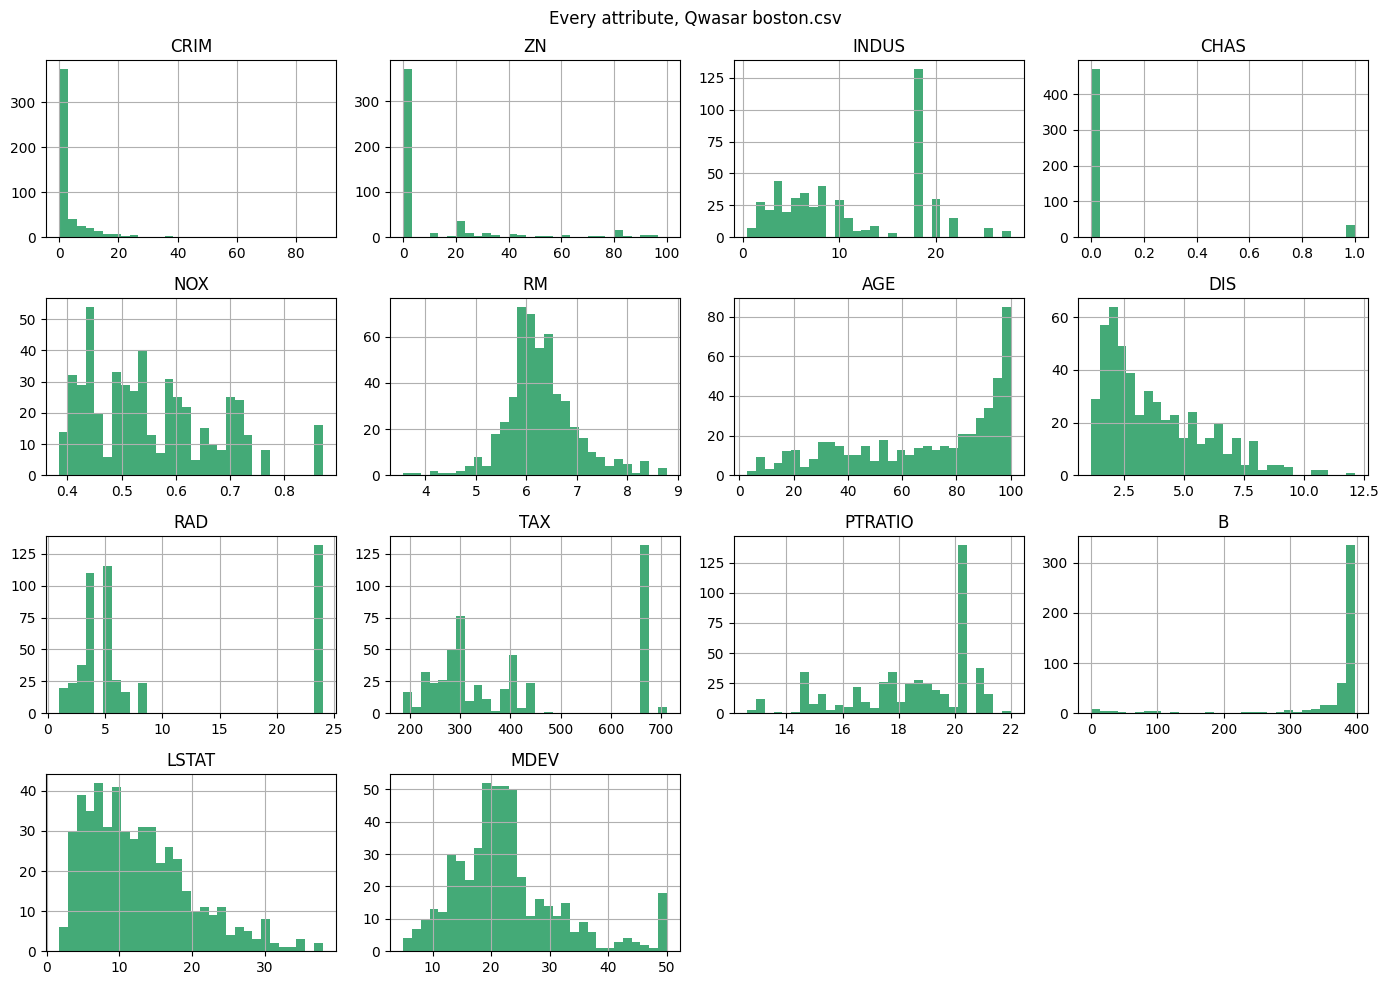

In [ ]:
def print_histograms(boston_dataframe):
    """One histogram per attribute."""
    boston_dataframe.hist(bins=30, figsize=(14, 10), color="#4a7")
    plt.suptitle("Every attribute, Qwasar boston.csv")
    plt.tight_layout()

print_histograms(boston_dataframe)

Read them as a set, and four shapes jump out:

- **`CHAS`** — two bars. A dummy variable, 93 % zero: almost no information to give.
- **`ZN`** — a spike at zero and a long thin tail. Three-quarters of towns are a single value.
- **`RAD` and `TAX`** — a normal-looking body plus an isolated block far to the right. That is the
  132-town cluster you found, not a smooth distribution.
- **`MDEV`** — right-skewed, with a visible **bar stacked on the right edge**: the censoring,
  drawn.

**The punchline:** the histogram of your target told you about the ceiling before any model did.
That is why the project asks for it before the modelling half.

## 4. `compute_correlations_matrix`

The subject wants Pearson correlations between every pair, and asks two questions directly:
which attribute correlates most with the median value, and which is most negative.

In [ ]:
def compute_correlations_matrix(boston_dataframe):
    """Pearson correlation between every pair of attributes."""
    return boston_dataframe.corr()

correlations = compute_correlations_matrix(boston_dataframe)
target_corr = correlations[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("correlation with", TARGET)
print(target_corr.round(3).to_string())

correlation with MDEV
LSTAT     -0.738
RM         0.695
PTRATIO   -0.508
INDUS     -0.484
TAX       -0.469
NOX       -0.427
CRIM      -0.386
RAD       -0.382
AGE       -0.377
ZN         0.360
B          0.333
DIS        0.250
CHAS       0.175


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("a full matrix", lambda: correlations.shape == (14, 14))
check("RM is the strongest positive", lambda: correlations[TARGET].drop(TARGET).idxmax() == "RM")
check("LSTAT is the strongest negative", lambda: correlations[TARGET].drop(TARGET).idxmin() == "LSTAT")

  a full matrix: PASS
  RM is the strongest positive: PASS
  LSTAT is the strongest negative: PASS


True

The two answers the subject asks for:

- **RM, +0.695** — more rooms, higher price. Unsurprising, and a good sanity check that the data
  behaves.
- **LSTAT, −0.738** — the percentage of "lower status" population, and it is the *strongest*
  relationship in the dataset, stronger than the number of rooms. Poorer town, cheaper houses.

And now the trap, which is not a statistical one.

`B` is defined in the subject as `1000(Bk - 0.63)²`, where Bk is the proportion of Black residents.
That is a racial variable, transformed so that its relationship to price is deliberately
non-monotonic. scikit-learn **removed this dataset entirely in version 1.2** over exactly this.

You still have to deliver the project. What you can do is treat `B` as what it is: name it in your
notebook, note that it encodes race, and check whether your model needs it at all. Dropping a
feature for a reason that is not statistical is a legitimate, defensible decision — as long as you
write down that you made it.

**Rule of thumb:** a column is not just numbers. Know what it measures before you feed it to a model.

## 5. `print_scatter_matrix`

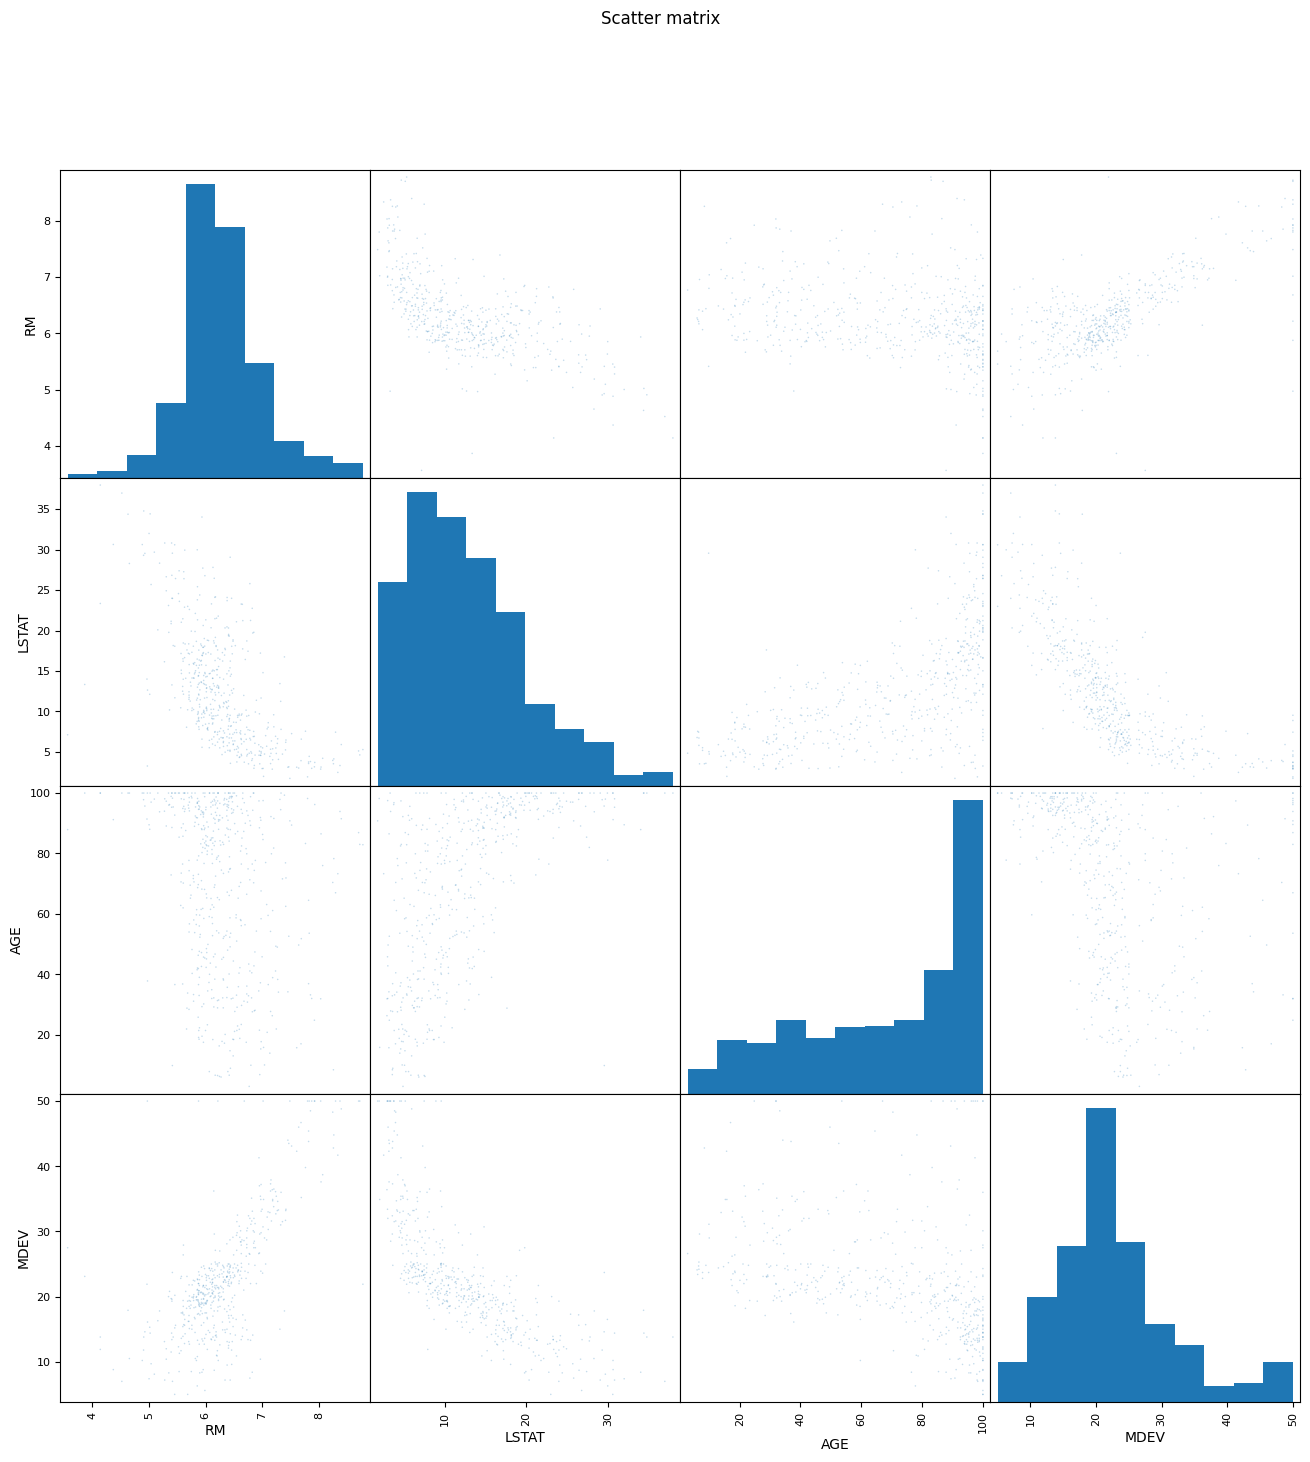

In [ ]:
def print_scatter_matrix(boston_dataframe):
    """Every attribute against every other; histograms on the diagonal."""
    pd.plotting.scatter_matrix(boston_dataframe, figsize=(16, 16), diagonal="hist", alpha=0.25, s=5)
    plt.suptitle("Scatter matrix")

# Four columns is enough to read on a screen; your submission should show them all.
cols = ["RM", "LSTAT", "AGE"] + ([TARGET] if TARGET in boston_dataframe.columns else [])
print_scatter_matrix(boston_dataframe[cols])

Look at the bottom row — the target against each feature — and specifically at the **flat line of
points along the top of every one of those panels**. Those are the sixteen censored towns, sitting
at exactly 50 regardless of their rooms, their LSTAT, their age. No feature explains them, because
their real values were erased.

`RM` against the target shows the upward trend the subject predicts. `LSTAT` shows a clear
downward **curve** — not a straight line, which is already a warning for the linear model you are
about to fit.

## What to take away

1. **Copy column names from the data, never from the documentation.** The file says `MDEV`.
2. **"No missing values" is a finding, not a conclusion.** Nothing was missing here and plenty was
   wrong.
3. **A spike at a round maximum means censoring.** 16 towns at exactly 50.0, and you cannot undo it.
4. **Histograms before models.** The ceiling, the dead `CHAS` column and the RAD/TAX block are all
   visible in one figure.
5. **LSTAT beats RM** as a predictor (−0.738 vs +0.695), and the LSTAT relationship is curved.
6. **Know what your columns mean.** `B` encodes race; decide deliberately and say so.

### Take it home
Finish the five analysis functions on the full dataset and print the correlations of every
attribute against `MDEV`. Bring two numbers next session: the correlation you did not expect, and
the number of towns sitting at the ceiling.